In [ ]:
!pip install -q squidpy

In [ ]:
import scanpy as sc
import squidpy as sq
import numpy as np
import anndata as ad
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
import scipy.io
import os
import re

In [ ]:
# Mount drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Moffit, et al data loading
The dataset used to train the models comes from a popular dataset in spatial transcriptomics presented in the paper *Molecular, spatial, and functional single-cell profiling of the hypothalamic preoptic region, Moffit et al*.

It contains data coming from a single cell RNA-seq experiment that profiled approximately 31,000 cells and a spatial transcriptomics experiment that imaged almost 1.1 Million single cells within intact tissues using MERFISH.

The study aimed at investigating the molecular, spatial, and functional organization of the mouse hypothalamic preoptic region.

Importantly, both datasets have been manually annotated in the experiments, meaning that cell types ground truth is available for downstream classification.

## Spatial data

The spatial dataset can be retrieved directly from the sc-ST python package **Squidpy** APIs. It contains a subset of pre-processed samples from the original paper data:

In [ ]:
# Load MERFISH AnnData
adata_st = sq.datasets.merfish()
print(adata_st)
# already pre-processed

AnnData object with n_obs × n_vars = 73655 × 161
    obs: 'Cell_ID', 'Animal_ID', 'Animal_sex', 'Behavior', 'Bregma', 'Centroid_X', 'Centroid_Y', 'Cell_class', 'Neuron_cluster_ID', 'batch'
    uns: 'Cell_class_colors'
    obsm: 'spatial', 'spatial3d'


Data has already undergone some processing, including a normalization procedure. Before proceeding we need to check wheter or not expression levels are already log-transformed.

In [ ]:
# Check if values look log-transformed (non-integer, no zeros)
print(f"Min value: {np.min(adata_st.X)}, Max value: {np.max(adata_st.X)}")
print(f"Average expression level per cell: {np.mean((adata_st.X > 0).sum(1))}")

Min value: 0.0, Max value: 369.5953674316406
Average expression level per cell: 63.27302966533161


These values suggested that data is not log-transforemd (very broad range) nor z-transformed (not zero centered) and has float values (not raw counts) plausible with total-count normalization achievable with **scanpy.pp.normalize_total()**.

## scRNA data
Single cell RNA-seq data can be retrieved from the **Gene Expression Omnibus (GEO)** portal of the NCBI/NLM/NIH with the following search query/GEO Accession: *GSE113576*.

To temporarely fetch data in the Colab VM and store it in an AnnData object, we create a directory and use the **file transfer protocol** to access directly the downloadable data directly from the terminal:

In [ ]:
!mkdir -p moffitt_scrna
!cd moffitt_scrna

!mkdir -p moffitt_scrna

!wget -P moffitt_scrna \
  ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE113nnn/GSE113576/suppl/GSE113576_barcodes.tsv.gz

!wget -P moffitt_scrna \
  ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE113nnn/GSE113576/suppl/GSE113576_genes.tsv.gz

!wget -P moffitt_scrna \
  ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE113nnn/GSE113576/suppl/GSE113576_matrix.mtx.gz



--2025-07-27 08:34:45--  ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE113nnn/GSE113576/suppl/GSE113576_barcodes.tsv.gz
           => ‘moffitt_scrna/GSE113576_barcodes.tsv.gz.1’
Resolving ftp.ncbi.nlm.nih.gov (ftp.ncbi.nlm.nih.gov)... 130.14.250.7, 130.14.250.11, 130.14.250.12, ...
Connecting to ftp.ncbi.nlm.nih.gov (ftp.ncbi.nlm.nih.gov)|130.14.250.7|:21... connected.
Logging in as anonymous ... Logged in!
==> SYST ... done.    ==> PWD ... done.
==> TYPE I ... done.  ==> CWD (1) /geo/series/GSE113nnn/GSE113576/suppl ... done.
==> SIZE GSE113576_barcodes.tsv.gz ... 126553
==> PASV ... done.    ==> RETR GSE113576_barcodes.tsv.gz ... done.
Length: 126553 (124K) (unauthoritative)

GSE113576_barcodes. 100%[===================>] 123.59K   176KB/s    in 0.7s    

2025-07-27 08:34:48 (176 KB/s) - ‘moffitt_scrna/GSE113576_barcodes.tsv.gz.1’ saved [126553]

--2025-07-27 08:34:48--  ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE113nnn/GSE113576/suppl/GSE113576_genes.tsv.gz
           => ‘moffitt_scrna/GSE

In [ ]:
# Read fetched files (different file types)
matrix = scipy.io.mmread("moffitt_scrna/GSE113576_matrix.mtx.gz").T.tocsc()
genes = pd.read_csv("moffitt_scrna/GSE113576_genes.tsv.gz", sep="\t", header=None)
barcodes = pd.read_csv("moffitt_scrna/GSE113576_barcodes.tsv.gz", header=None, sep="\t")

# Create sc annData object and load data
adata_sc = ad.AnnData(X=matrix)
adata_sc.var_names = genes[1].astype(str)
adata_sc.obs_names = barcodes[0].astype(str)
print(adata_sc)

AnnData object with n_obs × n_vars = 31299 × 27998


# Training genes set
All models require the two datasets to share the feature space, meaning that we are going to train them only on the subset of common genes in the two modalities.

This allows us to subset the whole AnnData objects to the selected columns/variables (after pre-processing):

Before subsetting, we must check for feature duplicates and remove them:

In [ ]:
print(f"Duplicates in adata_scrna.var_names: {adata_sc.var_names.duplicated().sum()}")
print(f"Duplicates in adata_merfish.var_names: {adata_st.var_names.duplicated().sum()}")

Duplicates in adata_scrna.var_names: 65
Duplicates in adata_merfish.var_names: 0


In [ ]:
# Remove duplicates
adata_sc = adata_sc[:, ~adata_sc.var_names.duplicated()].copy()

In [ ]:
# Get intersection
common_genes = adata_st.var_names.intersection(adata_sc.var_names)
common_genes

Index(['Ace2', 'Adora2a', 'Aldh1l1', 'Amigo2', 'Ano3', 'Aqp4', 'Ar',
       'Arhgap36', 'Avpr1a', 'Avpr2',
       ...
       'Penk', 'Scg2', 'Sln', 'Sst', 'Tac1', 'Tac2', 'Th', 'Trh', 'Ucn3',
       'Vgf'],
      dtype='object', length=155)

In [ ]:
# Match genes between MERFISH and scRNA-seq
adata_sc = adata_sc[:, common_genes].copy()
adata_st = adata_st[:, common_genes].copy()

In [ ]:
adata_sc

AnnData object with n_obs × n_vars = 31299 × 155

# Cell types
For the downstream classification task of cell types, we need ground truth labels.

Spatial data already contains labels at:

In [ ]:
adata_st.obs['Cell_class'].unique()

['OD Mature 2', 'OD Immature 1', 'Inhibitory', 'Excitatory', 'Microglia', ..., 'OD Mature 4', 'Pericytes', 'OD Mature 3', 'Ependymal', 'OD Immature 2']
Length: 16
Categories (16, object): ['Ambiguous', 'Astrocyte', 'Endothelial 1', 'Endothelial 2', ...,
                          'OD Mature 2', 'OD Mature 3', 'OD Mature 4', 'Pericytes']

For sc data, instead, lables are not provided in the GEO portal, but are publicly available in an *.xsls* file present in the supplementary material of the Moffit et al paper.

The file is downloaded and accesed from the mounted drive:

In [ ]:
xls_path = "/content/drive/MyDrive/Colab Notebooks/NNDL Project/data/aau5324_moffitt_table-s1.xlsx"
df = pd.read_excel(xls_path, header=1)  # Column names are in the first row, not header
df.head()

,Cell name,Sex,Replicate number,Cell class (determined from clustering of all cells),Non-neuronal cluster (determined from clustering of all cells),Neuronal cluster (determined from clustering of inhibitory or excitatory neurons)
0,AAACCTGAGATGTGGC-1,Female,1,Fibroblast,Fibroblast 1,NaN
1,AAACCTGCACACAGAG-1,Female,1,Excitatory,NaN,e17:Th/Adcyap1
2,AAACCTGCACTACAGT-1,Female,1,Inhibitory,NaN,i6:Avp/Nms
3,AAACCTGTCAGGATCT-1,Female,1,Excitatory,NaN,e16:Sst/Cartpt
4,AAACCTGTCGCACTCT-1,Female,1,Mature oligodendrocyte,Mature oligodendrocyte 3,NaN


In [ ]:
# Rename columns to match spatial
df = df.rename(columns={
    "Cell name": "Cell_ID",
    "Replicate number": "Replicate_number",
    "Cell class (determined from clustering of all cells)": "Cell_class",
    "Non-neuronal cluster (determined from clustering of all cells)": "Non-neuronal_cluster_ID",
    "Neuronal cluster (determined from clustering of inhibitory or excitatory neurons)": "Neuronal_cluster_ID"
})
df.head()

,Cell_ID,Sex,Replicate_number,Cell_class,Non-neuronal_cluster_ID,Neuronal_cluster_ID
0,AAACCTGAGATGTGGC-1,Female,1,Fibroblast,Fibroblast 1,NaN
1,AAACCTGCACACAGAG-1,Female,1,Excitatory,NaN,e17:Th/Adcyap1
2,AAACCTGCACTACAGT-1,Female,1,Inhibitory,NaN,i6:Avp/Nms
3,AAACCTGTCAGGATCT-1,Female,1,Excitatory,NaN,e16:Sst/Cartpt
4,AAACCTGTCGCACTCT-1,Female,1,Mature oligodendrocyte,Mature oligodendrocyte 3,NaN


Now we need to include this additional data in the sc AnnData object:

In [ ]:
# Convert to string
df["Cell_ID"] = df["Cell_ID"].astype(str)
adata_sc.obs_names = adata_sc.obs_names.astype(str)

# Make cell ids indexes
df = df.set_index("Cell_ID")

# Join df to the left
adata_sc.obs = adata_sc.obs.join(df, how="left")
adata_sc

AnnData object with n_obs × n_vars = 31299 × 155
    obs: 'Sex', 'Replicate_number', 'Cell_class', 'Non-neuronal_cluster_ID', 'Neuronal_cluster_ID'

In [ ]:
adata_sc.obs['Cell_class'].unique()

array(['Fibroblast', 'Excitatory', 'Inhibitory', 'Mature oligodendrocyte',
       'Endothelial', 'Immature oligodendrocyte', 'Microglia',
       'Ambiguous', 'Mural', 'Newly formed oligodendrocyte', 'Astrocytes',
       'Unstable', 'Macrophage', 'Ependymal'], dtype=object)

Before identifying the shared cell types pool between the two modalities, we need to make some manipulation in order to have a coherent nomenclature in the two datasets.

As we can see, at the moment, they do not match exaclty:

In [ ]:
print("ST labels:")
for label in adata_st.obs['Cell_class'].unique():
  print(label)
print("\n")
print("SC labels:")
for label in adata_sc.obs['Cell_class'].unique():
  print(label)

ST labels:
OD Mature 2
OD Immature 1
Inhibitory
Excitatory
Microglia
Ambiguous
Astrocyte
Endothelial 2
Endothelial 3
Endothelial 1
OD Mature 1
OD Mature 4
Pericytes
OD Mature 3
Ependymal
OD Immature 2


SC labels:
Fibroblast
Excitatory
Inhibitory
Mature oligodendrocyte
Endothelial
Immature oligodendrocyte
Microglia
Ambiguous
Mural
Newly formed oligodendrocyte
Astrocytes
Unstable
Macrophage
Ependymal


In [ ]:
# Match cell type names
def merge_subtypes(label):
    # Strip numeric suffixes from known categories
    if re.match(r"Endothelial \d+", label):
        return "Endothelial"
    elif re.match(r"OD Mature \d+", label):
        return "OD Mature"
    elif re.match(r"OD Immature \d+", label):
        return "OD Immature"
    else:
        return label

adata_st.obs["Cell_class"] = adata_st.obs["Cell_class"].apply(merge_subtypes)

# Adjust names
adata_st.obs["Cell_class"] = (
    adata_st.obs["Cell_class"].replace({
        "OD Mature": "Mature oligodendrocyte",
        "OD Immature": "Immature oligodendrocyte"
    })
    )

In [ ]:
# Check
print("ST labels:")
for label in adata_st.obs['Cell_class'].unique():
  print(label)
print("\n")
print("SC labels:")
for label in adata_sc.obs['Cell_class'].unique():
  print(label)

ST labels:
Mature oligodendrocyte
Immature oligodendrocyte
Inhibitory
Excitatory
Microglia
Ambiguous
Astrocyte
Endothelial
Pericytes
Ependymal


SC labels:
Fibroblast
Excitatory
Inhibitory
Mature oligodendrocyte
Endothelial
Immature oligodendrocyte
Microglia
Ambiguous
Mural
Newly formed oligodendrocyte
Astrocytes
Unstable
Macrophage
Ependymal


Now that nomenclature is coherent we are goin to subset the observetions to the intersection.

This ensure two things:
1. For classification, there are no mismatches in labels from the training set and test set

2. During alignmemnt, we ensure that all spatial observations have biological matches in the sc data.

For both sets, we are also dropping the 'Ambiguous' cell type to avoid introducing confounding observations in the models.

In [ ]:
# Get the unique cell types in both datasets
types_sc = set(adata_sc.obs['Cell_class'].unique())
types_spatial = set(adata_st.obs['Cell_class'].unique())

# Exclude 'Ambiguous' from both
types_sc.discard('Ambiguous')
types_spatial.discard('Ambiguous')

# Find the intersection (cell types present in both)
common_cell_types = types_sc & types_spatial

print("Common cell types:", common_cell_types)

# Subset both AnnData objects to only include those cell types
adata_sc = adata_sc[adata_sc.obs['Cell_class'].isin(common_cell_types)].copy()
adata_st = adata_st[adata_st.obs['Cell_class'].isin(common_cell_types)].copy()

Common cell types: {'Ependymal', 'Mature oligodendrocyte', 'Inhibitory', 'Immature oligodendrocyte', 'Microglia', 'Endothelial', 'Excitatory'}


In [ ]:
print("SC final observations:", adata_sc.shape[0])

SC final observations: 28390


In [ ]:
print("ST final observations:", adata_st.shape[0])

ST final observations: 55342


## Spatial patch
In order to obtain a more managable data size and construct a spatial set of observations that is of smaller cardinality than the single cell (allows for a many to one alignment), we perform spatial patching.

This procedure consists of extracting a subset of spatial samples close in space, effectively idenitfying a tissue patch.

In [ ]:
def sample_spatial_patch(adata, sample_size=1e4, seed=42):
    coords = adata.obsm["spatial"]
    n_obs = adata.n_obs

    # Pick a random seed spot as center
    np.random.seed(seed)
    center_idx = np.random.choice(n_obs)
    center_coord = coords[center_idx].reshape(1, -1)

    # Find k-nearest neighbors
    nbrs = NearestNeighbors(n_neighbors=sample_size, algorithm='ball_tree')
    nbrs.fit(coords)
    _, indices = nbrs.kneighbors(center_coord)

    # Subset the AnnData object
    return adata[indices[0]].copy()


In [ ]:
adata_st = sample_spatial_patch(adata_st, sample_size=10000, seed=42)
adata_st

AnnData object with n_obs × n_vars = 10000 × 155
    obs: 'Cell_ID', 'Animal_ID', 'Animal_sex', 'Behavior', 'Bregma', 'Centroid_X', 'Centroid_Y', 'Cell_class', 'Neuron_cluster_ID', 'batch'
    uns: 'Cell_class_colors'
    obsm: 'spatial', 'spatial3d'

We are going to look at the histogram of absoulte frequencies in both modalities to get a glimpse of the counts:

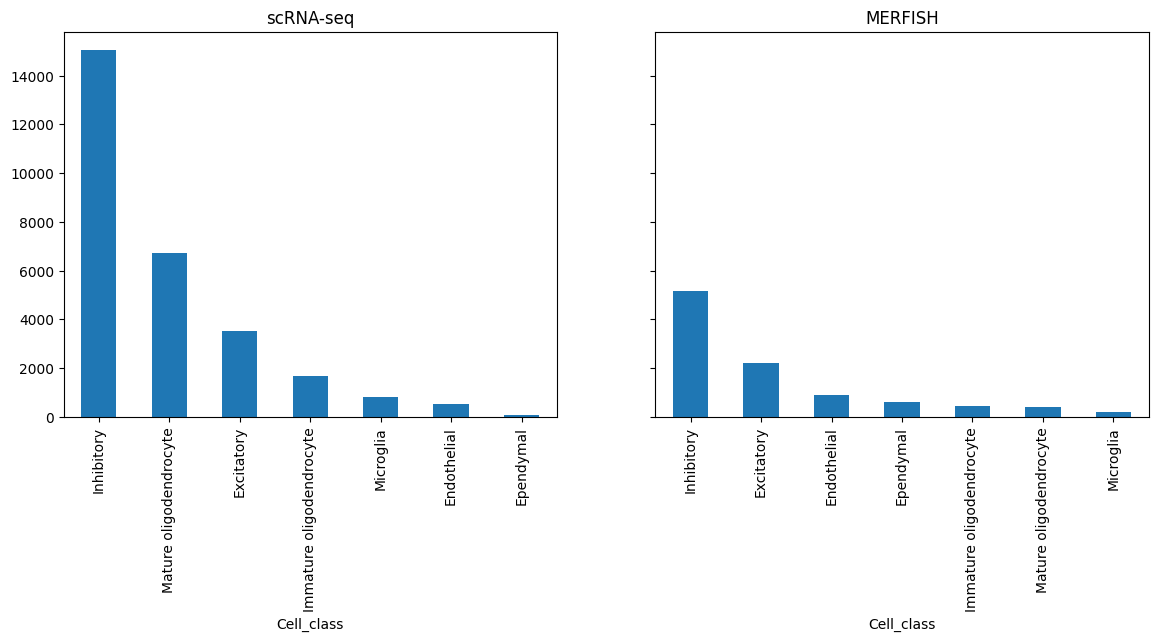

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
adata_sc.obs['Cell_class'].value_counts().plot.bar(ax=axes[0], title="scRNA-seq")
adata_st.obs['Cell_class'].value_counts().plot.bar(ax=axes[1], title="MERFISH")
plt.savefig('/content/drive/My Drive/Colab Notebooks/NNDL Project/figures/cell_type_frequencies.png', bbox_inches='tight')
plt.show()

# Pre-precessing
For the alignment phase inspired by Tangram, literature shows that raw counts work best.

In our case, alignment takes place on an encoded latent space and computed similarities (in all models) are noralized by definition.

For this reason, both datasets undergo the following pre-precessing pipeline:

1. Total-count Normalization
 * For each cell, it divides all gene counts by the total number of transcripts in that cell, then multiplies by 10,000
 * Makes gene expression comparable across cells by removing differences in sequencing depth or library size

2. log1p Transform
 * Applies a $log(x + 1)$ transformation to every expression value
 * Compresses the dynamic range of the data: it shrinks large expression values while preserving smaller ones
 * Makes the data more Gaussian-like and helps dampen the effect of highly expressed genes dominating the signal

3. Z-score Normalization
 * For each gene, subtracts the mean and divides by the standard deviation, across all cells
 * Puts all genes on the same scale so that none dominate due to raw expression magnitude.

## Spatial
Spatial data has already done the first step:

In [ ]:
# log-transform and z-score
sc.pp.log1p(adata_st)
sc.pp.scale(adata_st)

/usr/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


## Single cell

In [ ]:
# Normalize, log-transform  and z-score
sc.pp.normalize_total(adata_sc)
sc.pp.log1p(adata_sc)
sc.pp.scale(adata_sc)

/usr/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


# Saving files to drive

In [ ]:
# Save spatial dataset
adata_st.write('/content/drive/My Drive/Colab Notebooks/NNDL Project/data/moffit_spatial_train.h5ad')

In [ ]:
# Save scRNA dataset
adata_sc.write('/content/drive/My Drive/Colab Notebooks/NNDL Project/data/moffit_scRNA_train.h5ad')